In [1]:
import numpy as np
import torch

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# 0. Choosing "teacher" model

In [2]:
checkpoint = "bert-base-uncased"
task_name  = "rte"

# 1. Loading our mrpc part of the GLUE dataset

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

raw_datasets = load_dataset("glue", task_name)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating test split: 100%|██████████| 3000/3000 [00:00<00:00, 1026925.00 examples/s]


In [4]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 2490
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 277
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3000
    })
})

In [5]:
raw_datasets['train']

Dataset({
    features: ['sentence1', 'sentence2', 'label', 'idx'],
    num_rows: 2490
})

In [6]:
from datasets import DatasetDict

In [7]:
raw_datasets = DatasetDict({
    "train": raw_datasets['train'],
    "validation": raw_datasets['validation'],
    "test": raw_datasets['test']
})

In [8]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 2490
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 277
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3000
    })
})

In [9]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[0]

{'sentence1': 'No Weapons of Mass Destruction Found in Iraq Yet.',
 'sentence2': 'Weapons of Mass Destruction Found in Iraq.',
 'label': 1,
 'idx': 0}

In [10]:
raw_train_dataset[5]['sentence1'], raw_train_dataset[5]['sentence2']

('Britain said, Friday, that it has barred cleric, Omar Bakri, from returning to the country from Lebanon, where he was released by police after being detained for 24 hours.',
 'Bakri was briefly detained, but was released.')

In [11]:
raw_train_dataset[5]['label']

0

In [12]:
raw_train_dataset[5]['idx']

5

In [13]:
raw_train_dataset.features

{'sentence1': Value('string'),
 'sentence2': Value('string'),
 'label': ClassLabel(names=['entailment', 'not_entailment']),
 'idx': Value('int32')}

# 2. Preprocess

In [14]:
def tokenize_function(example):
    return tokenizer(example["sentence1"], example["sentence2"], truncation=True)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
tokenized_datasets

Map: 100%|██████████| 3000/3000 [00:00<00:00, 40595.93 examples/s]


DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2490
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 277
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3000
    })
})

# 3. Preparing for Training

In [15]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [16]:
tokenized_datasets = tokenized_datasets.remove_columns(["sentence1", "sentence2", "idx"])
tokenized_datasets = tokenized_datasets.rename_column("label", "labels")
tokenized_datasets.set_format("torch")
tokenized_datasets["train"].column_names

['labels', 'input_ids', 'token_type_ids', 'attention_mask']

In [17]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    tokenized_datasets["train"], shuffle=True, batch_size=32, collate_fn=data_collator
)

val_dataloader = DataLoader(
    tokenized_datasets["validation"], batch_size=32, collate_fn=data_collator
)

eval_dataloader = DataLoader(
    tokenized_datasets["test"], batch_size=32, collate_fn=data_collator
)

In [18]:
for batch in train_dataloader:
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 167]),
 'token_type_ids': torch.Size([32, 167]),
 'attention_mask': torch.Size([32, 167])}

# 4. Load Model

In [19]:
import sys
sys.path.insert(0, '../')

In [20]:
from Bert_model.modeling_bert import BertForSequenceClassification

In [21]:
# id2label, label2id dicts for the outputs for the model
labels = tokenized_datasets["train"].features["labels"].names
num_labels = len(labels)
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = str(i)
    id2label[str(i)] = label

In [22]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [23]:
model.set_use_module_grafting(False)
model.set_use_scc_status(False)

In [24]:
outputs = model(**batch)
print(outputs.loss, outputs.logits.shape)

tensor(0.8105, grad_fn=<NllLossBackward0>) torch.Size([32, 2])


In [25]:
outputs.keys()

odict_keys(['loss', 'logits', 'hidden_states', 'attentions'])

In [26]:
device = torch.device("cuda:1") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)

device

device(type='cuda', index=1)

In [27]:
len(outputs.hidden_states['hidden_states']), outputs.hidden_states['hidden_states'][0].shape

(13, torch.Size([32, 167, 768]))

In [28]:
len(outputs.attentions['attention_head'])

12

In [29]:
outputs.attentions['attention_head'][0].shape

torch.Size([32, 12, 167, 167])

In [30]:
len(outputs.attentions["pre_wo"])

12

In [31]:
outputs.attentions["pre_wo"][0].shape

torch.Size([32, 167, 768])

In [32]:
outputs.attentions["attention_output"][0].shape

torch.Size([32, 167, 768])

### Loading Trained Weights

In [33]:
load_path = '../glue_fine_tune/weights/'
best_weight = torch.load(load_path + f'bert-{task_name}.pt', map_location=device)
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [34]:
from train_eval_func import eval_loop

In [35]:
eval_loop(model, val_dataloader, task_name, device)[0]

{'accuracy': 0.6859205776173285}

# 5. Similarity Analysis

In [36]:
from CKA import CKAEvaluator

cka_eval = CKAEvaluator(device)

In [37]:
from CKA import SentenceCKARedundancy

headsCka_eval = SentenceCKARedundancy(device)

In [38]:
def adjacent_similarity_stats(
    similarity_scores, 
    thresold = 0.80,
    disp_sim_score=True, 
    disp_group_count=True
):
    adj_similarities = []
    for i in range(1, len(similarity_scores)):
        adj_similarities.append(similarity_scores[i-1][i])

    if disp_sim_score:
        print("Similarity Scores:", adj_similarities)

    high_pair_count = 0
    for pair in adj_similarities:
        if pair > thresold:
            high_pair_count += 1
    
    if disp_group_count:
        print("Number of High Similar Pairs:", high_pair_count)

    return adj_similarities, high_pair_count

### Using Training Data on CLS Token only

In [39]:
reps_similarity, atts_similarity, mha_similarity, pre_wo_similarity, sub_similarity, pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
pre_wo_stats = cka_eval.similarity_stats(pre_wo_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)
pre_wo_subs_stats = cka_eval.similarity_stats(pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {pre_wo_stats['average']:.6f}")
print(f"    Highest: {pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 78/78 [00:43<00:00,  1.80it/s]

  Reps Similarity Stats:
    Average: 0.878027
    Highest: 0.961511
    Lowest:  0.573684

  Atts Similarity Stats:
    Average: 0.969285
    Highest: 0.996458
    Lowest:  0.915149
  MHA Similarity Stats:
    Average: 0.899426
    Highest: 0.974467
    Lowest:  0.683253
  Pre Wo Similarity Stats:
    Average: 0.832270
    Highest: 0.908178
    Lowest:  0.725587
  Sublayer Similarity Stats:
    Average: 0.935005
    Highest: 0.985805
    Lowest:  0.675796
  Pre Wo Sublayer Similarity Stats:
    Average: 0.868410
    Highest: 0.952589
    Lowest:  0.752945


In [40]:
sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

sub_out_stats = cka_eval.similarity_stats(sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {sub_out_stats['average']:.6f}")
print(f"    Highest: {sub_out_stats['max']:.6f}")
print(f"    Lowest:  {sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 78/78 [00:29<00:00,  2.66it/s]

  Sub Out Similarity Stats:
    Average: 0.895892
    Highest: 0.985676
    Lowest:  0.744196


In [41]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Layer')

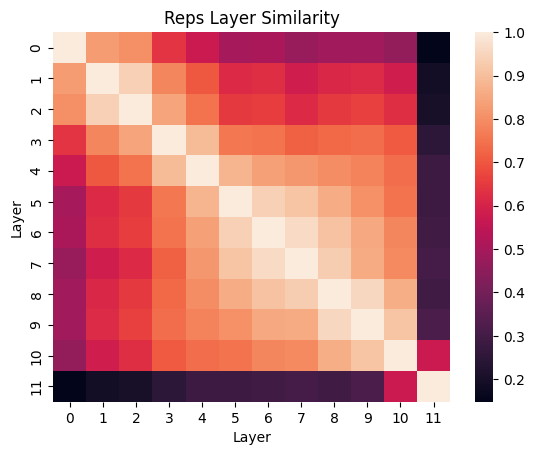

In [42]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [43]:
_,_ = adjacent_similarity_stats(reps_similarity)

Similarity Scores: [0.8300295, 0.93890315, 0.8459961, 0.89059156, 0.87812275, 0.9399145, 0.96151066, 0.9306195, 0.9555074, 0.91341656, 0.573684]
Number of High Similar Pairs: 10


In [44]:
_,_ = adjacent_similarity_stats(reps_similarity, thresold=0.85)

Similarity Scores: [0.8300295, 0.93890315, 0.8459961, 0.89059156, 0.87812275, 0.9399145, 0.96151066, 0.9306195, 0.9555074, 0.91341656, 0.573684]
Number of High Similar Pairs: 8


In [45]:
_,_ = adjacent_similarity_stats(reps_similarity, thresold=0.9)

Similarity Scores: [0.8300295, 0.93890315, 0.8459961, 0.89059156, 0.87812275, 0.9399145, 0.96151066, 0.9306195, 0.9555074, 0.91341656, 0.573684]
Number of High Similar Pairs: 6


Text(50.722222222222214, 0.5, 'Layer')

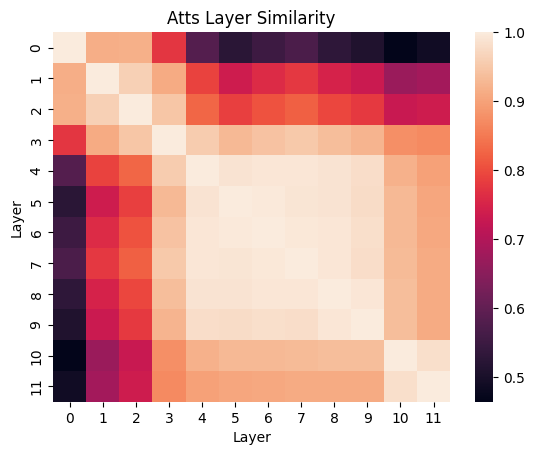

In [46]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [47]:
_,_ = adjacent_similarity_stats(atts_similarity)

Similarity Scores: [0.91514903, 0.96092546, 0.9456892, 0.95577544, 0.98774874, 0.9964583, 0.99563783, 0.9920302, 0.99344146, 0.9360892, 0.98319095]
Number of High Similar Pairs: 11


In [48]:
_,_ = adjacent_similarity_stats(atts_similarity, thresold=0.85)

Similarity Scores: [0.91514903, 0.96092546, 0.9456892, 0.95577544, 0.98774874, 0.9964583, 0.99563783, 0.9920302, 0.99344146, 0.9360892, 0.98319095]
Number of High Similar Pairs: 11


In [49]:
_,_ = adjacent_similarity_stats(atts_similarity, thresold=0.9)

Similarity Scores: [0.91514903, 0.96092546, 0.9456892, 0.95577544, 0.98774874, 0.9964583, 0.99563783, 0.9920302, 0.99344146, 0.9360892, 0.98319095]
Number of High Similar Pairs: 11


Text(50.722222222222214, 0.5, 'Layer')

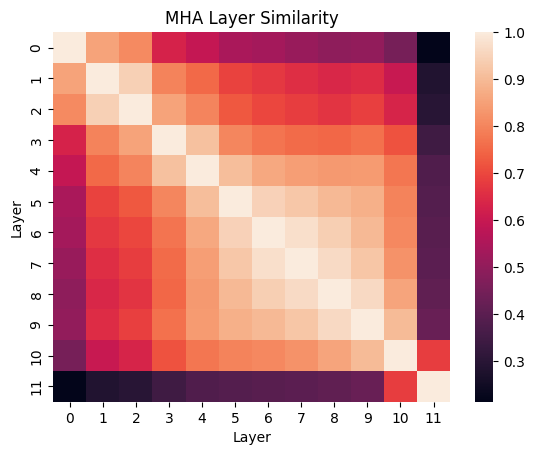

In [50]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [51]:
_,_ = adjacent_similarity_stats(mha_similarity)

Similarity Scores: [0.85279995, 0.9428351, 0.85273564, 0.9109628, 0.906179, 0.9466764, 0.9744673, 0.9631783, 0.9608663, 0.89972764, 0.68325263]
Number of High Similar Pairs: 10


In [52]:
_,_ = adjacent_similarity_stats(mha_similarity, thresold=0.85)

Similarity Scores: [0.85279995, 0.9428351, 0.85273564, 0.9109628, 0.906179, 0.9466764, 0.9744673, 0.9631783, 0.9608663, 0.89972764, 0.68325263]
Number of High Similar Pairs: 10


In [53]:
_,_ = adjacent_similarity_stats(mha_similarity, thresold=0.9)

Similarity Scores: [0.85279995, 0.9428351, 0.85273564, 0.9109628, 0.906179, 0.9466764, 0.9744673, 0.9631783, 0.9608663, 0.89972764, 0.68325263]
Number of High Similar Pairs: 7


Text(50.722222222222214, 0.5, 'Layer')

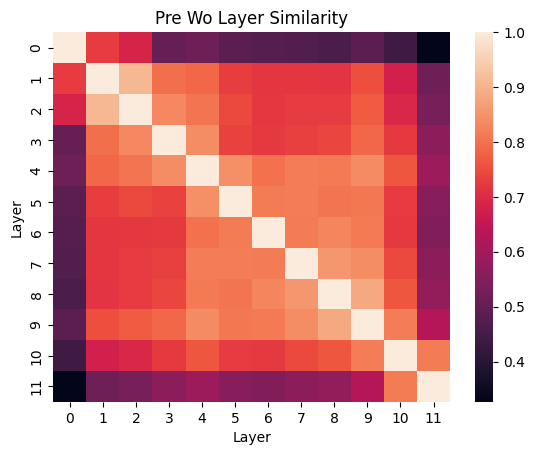

In [54]:
title = "Pre Wo Layer Similarity"
plt.title(title)
sn.heatmap(data = pre_wo_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [55]:
_,_ = adjacent_similarity_stats(pre_wo_similarity)

Similarity Scores: [0.7255867, 0.9081779, 0.8319725, 0.83969104, 0.84294665, 0.81460214, 0.8154403, 0.8563297, 0.8867308, 0.81810063, 0.8153963]
Number of High Similar Pairs: 10


In [56]:
_,_ = adjacent_similarity_stats(pre_wo_similarity, thresold=0.85)

Similarity Scores: [0.7255867, 0.9081779, 0.8319725, 0.83969104, 0.84294665, 0.81460214, 0.8154403, 0.8563297, 0.8867308, 0.81810063, 0.8153963]
Number of High Similar Pairs: 3


In [57]:
_,_ = adjacent_similarity_stats(pre_wo_similarity, thresold=0.9)

Similarity Scores: [0.7255867, 0.9081779, 0.8319725, 0.83969104, 0.84294665, 0.81460214, 0.8154403, 0.8563297, 0.8867308, 0.81810063, 0.8153963]
Number of High Similar Pairs: 1


Text(50.722222222222214, 0.5, 'Layer')

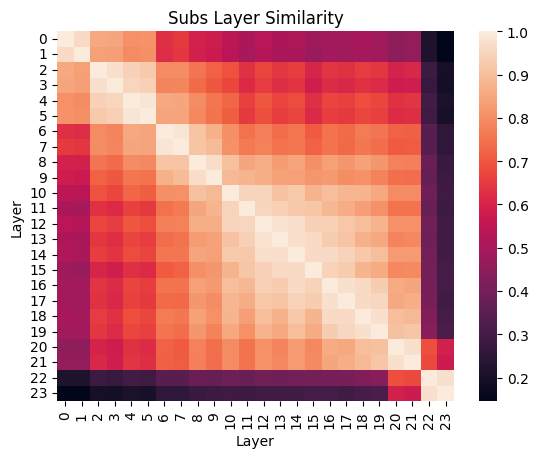

In [58]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [59]:
_,_ = adjacent_similarity_stats(sub_similarity)

Similarity Scores: [0.9617012, 0.8350832, 0.97392714, 0.9511151, 0.9858049, 0.8435014, 0.9843883, 0.91252697, 0.9671578, 0.88979435, 0.9474152, 0.95290554, 0.97844726, 0.9730926, 0.96040356, 0.94544613, 0.97360015, 0.9614934, 0.975491, 0.90545833, 0.97560716, 0.67579603, 0.97495407]
Number of High Similar Pairs: 22


In [60]:
_,_ = adjacent_similarity_stats(sub_similarity, thresold=0.85)

Similarity Scores: [0.9617012, 0.8350832, 0.97392714, 0.9511151, 0.9858049, 0.8435014, 0.9843883, 0.91252697, 0.9671578, 0.88979435, 0.9474152, 0.95290554, 0.97844726, 0.9730926, 0.96040356, 0.94544613, 0.97360015, 0.9614934, 0.975491, 0.90545833, 0.97560716, 0.67579603, 0.97495407]
Number of High Similar Pairs: 20


In [61]:
_,_ = adjacent_similarity_stats(sub_similarity, thresold=0.9)

Similarity Scores: [0.9617012, 0.8350832, 0.97392714, 0.9511151, 0.9858049, 0.8435014, 0.9843883, 0.91252697, 0.9671578, 0.88979435, 0.9474152, 0.95290554, 0.97844726, 0.9730926, 0.96040356, 0.94544613, 0.97360015, 0.9614934, 0.975491, 0.90545833, 0.97560716, 0.67579603, 0.97495407]
Number of High Similar Pairs: 19


Text(50.722222222222214, 0.5, 'Layer')

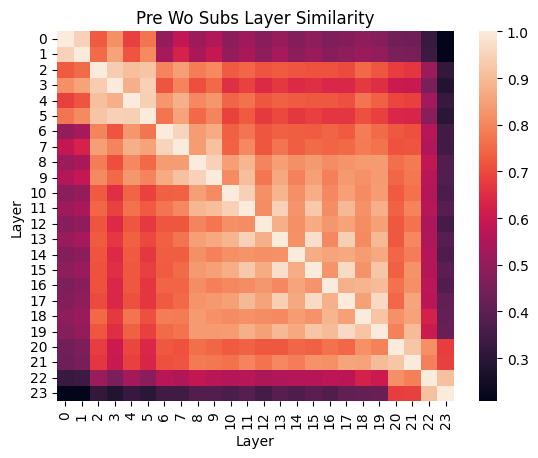

In [62]:
title = "Pre Wo Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = pre_wo_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [63]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity)

Similarity Scores: [0.94560474, 0.75294477, 0.9365106, 0.8766767, 0.9391484, 0.77003545, 0.9525887, 0.84181094, 0.9454202, 0.80834436, 0.94160247, 0.81244063, 0.8779617, 0.8183062, 0.8722771, 0.8240062, 0.88241833, 0.8464638, 0.91896605, 0.79011655, 0.92039657, 0.7884588, 0.9109408]
Number of High Similar Pairs: 19


In [64]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.94560474, 0.75294477, 0.9365106, 0.8766767, 0.9391484, 0.77003545, 0.9525887, 0.84181094, 0.9454202, 0.80834436, 0.94160247, 0.81244063, 0.8779617, 0.8183062, 0.8722771, 0.8240062, 0.88241833, 0.8464638, 0.91896605, 0.79011655, 0.92039657, 0.7884588, 0.9109408]
Number of High Similar Pairs: 13


In [65]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.94560474, 0.75294477, 0.9365106, 0.8766767, 0.9391484, 0.77003545, 0.9525887, 0.84181094, 0.9454202, 0.80834436, 0.94160247, 0.81244063, 0.8779617, 0.8183062, 0.8722771, 0.8240062, 0.88241833, 0.8464638, 0.91896605, 0.79011655, 0.92039657, 0.7884588, 0.9109408]
Number of High Similar Pairs: 9


Text(50.722222222222214, 0.5, 'Layer')

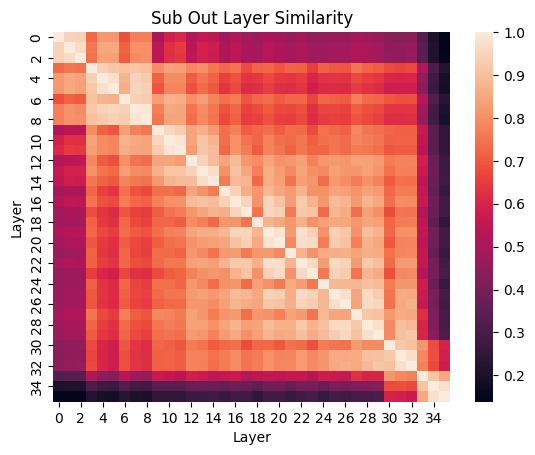

In [66]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [67]:
_,_ = adjacent_similarity_stats(sub_out_similarity)

Similarity Scores: [0.9450851, 0.9630777, 0.7441961, 0.9374968, 0.97422206, 0.86708003, 0.937888, 0.9856758, 0.7528428, 0.9529688, 0.9843713, 0.82796055, 0.9456881, 0.9675958, 0.7614391, 0.94120425, 0.9467134, 0.74866474, 0.8780901, 0.9786018, 0.7858457, 0.8728993, 0.9594482, 0.7553347, 0.88331556, 0.97357863, 0.84371936, 0.9189761, 0.97537357, 0.78949654, 0.92107326, 0.97541136, 0.7752177, 0.9107488, 0.97491497]
Number of High Similar Pairs: 27


In [68]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.94560474, 0.75294477, 0.9365106, 0.8766767, 0.9391484, 0.77003545, 0.9525887, 0.84181094, 0.9454202, 0.80834436, 0.94160247, 0.81244063, 0.8779617, 0.8183062, 0.8722771, 0.8240062, 0.88241833, 0.8464638, 0.91896605, 0.79011655, 0.92039657, 0.7884588, 0.9109408]
Number of High Similar Pairs: 13


In [69]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.94560474, 0.75294477, 0.9365106, 0.8766767, 0.9391484, 0.77003545, 0.9525887, 0.84181094, 0.9454202, 0.80834436, 0.94160247, 0.81244063, 0.8779617, 0.8183062, 0.8722771, 0.8240062, 0.88241833, 0.8464638, 0.91896605, 0.79011655, 0.92039657, 0.7884588, 0.9109408]
Number of High Similar Pairs: 9


### Using Val Data on CLS Token only

In [70]:
val_reps_similarity, val_atts_similarity, val_mha_similarity, val_pre_wo_similarity, val_sub_similarity, val_pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
val_reps_stats = cka_eval.similarity_stats(val_reps_similarity)
val_atts_stats = cka_eval.similarity_stats(val_atts_similarity)
val_mha_stats  = cka_eval.similarity_stats(val_mha_similarity)
val_pre_wo_stats = cka_eval.similarity_stats(val_pre_wo_similarity)
val_subs_stats = cka_eval.similarity_stats(val_sub_similarity)
val_pre_wo_subs_stats = cka_eval.similarity_stats(val_pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {val_reps_stats['average']:.6f}")
print(f"    Highest: {val_reps_stats['max']:.6f}")
print(f"    Lowest:  {val_reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {val_atts_stats['average']:.6f}")
print(f"    Highest: {val_atts_stats['max']:.6f}")
print(f"    Lowest:  {val_atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {val_mha_stats['average']:.6f}")
print(f"    Highest: {val_mha_stats['max']:.6f}")
print(f"    Lowest:  {val_mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {val_pre_wo_stats['average']:.6f}")
print(f"    Highest: {val_pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {val_pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {val_subs_stats['average']:.6f}")
print(f"    Highest: {val_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {val_pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {val_pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 9/9 [00:04<00:00,  1.82it/s]

  Reps Similarity Stats:
    Average: 0.881614
    Highest: 0.960552
    Lowest:  0.537533

  Atts Similarity Stats:
    Average: 0.969133
    Highest: 0.996464
    Lowest:  0.916598
  MHA Similarity Stats:
    Average: 0.908089
    Highest: 0.975248
    Lowest:  0.694655
  Pre Wo Similarity Stats:
    Average: 0.845652
    Highest: 0.911251
    Lowest:  0.731229
  Sublayer Similarity Stats:
    Average: 0.938963
    Highest: 0.987043
    Lowest:  0.695740
  Pre Wo Sublayer Similarity Stats:
    Average: 0.877824
    Highest: 0.955757
    Lowest:  0.756530


In [71]:
val_sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

val_sub_out_stats = cka_eval.similarity_stats(val_sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {val_sub_out_stats['average']:.6f}")
print(f"    Highest: {val_sub_out_stats['max']:.6f}")
print(f"    Lowest:  {val_sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 9/9 [00:03<00:00,  2.68it/s]

  Sub Out Similarity Stats:
    Average: 0.902726
    Highest: 0.987043
    Lowest:  0.746232


Text(50.722222222222214, 0.5, 'Layer')

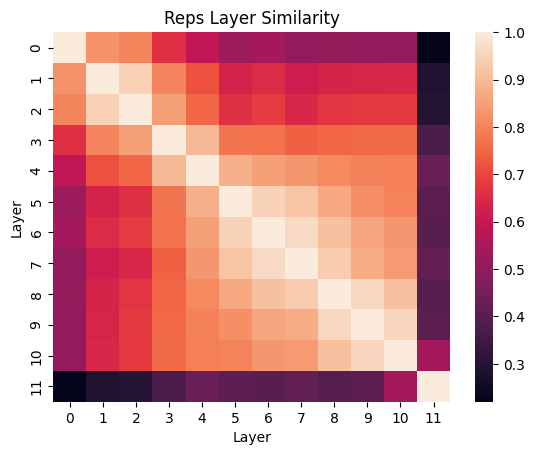

In [72]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = val_reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [73]:
_,_ = adjacent_similarity_stats(val_reps_similarity)

Similarity Scores: [0.82620776, 0.9434632, 0.8495792, 0.89733887, 0.8813794, 0.94886726, 0.96055156, 0.9355071, 0.9599793, 0.9573487, 0.5375325]
Number of High Similar Pairs: 10


In [74]:
_,_ = adjacent_similarity_stats(val_reps_similarity, thresold=0.85)

Similarity Scores: [0.82620776, 0.9434632, 0.8495792, 0.89733887, 0.8813794, 0.94886726, 0.96055156, 0.9355071, 0.9599793, 0.9573487, 0.5375325]
Number of High Similar Pairs: 8


In [75]:
_,_ = adjacent_similarity_stats(val_reps_similarity, thresold=0.9)

Similarity Scores: [0.82620776, 0.9434632, 0.8495792, 0.89733887, 0.8813794, 0.94886726, 0.96055156, 0.9355071, 0.9599793, 0.9573487, 0.5375325]
Number of High Similar Pairs: 6


Text(50.722222222222214, 0.5, 'Layer')

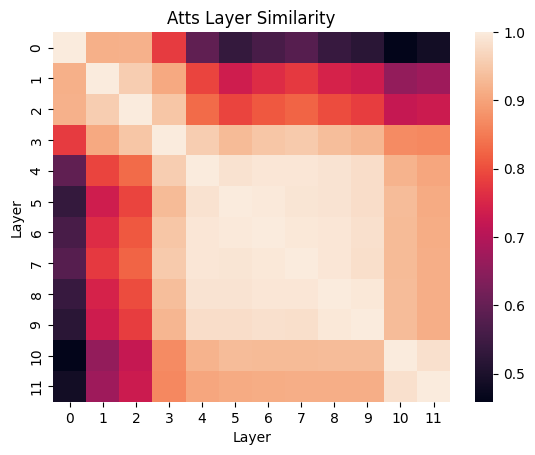

In [76]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = val_atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [77]:
_,_ = adjacent_similarity_stats(val_atts_similarity)

Similarity Scores: [0.9165979, 0.95634705, 0.9467306, 0.95672786, 0.98727345, 0.9964643, 0.9955928, 0.9923849, 0.9937175, 0.93447757, 0.98414487]
Number of High Similar Pairs: 11


In [78]:
_,_ = adjacent_similarity_stats(val_atts_similarity, thresold=0.85)

Similarity Scores: [0.9165979, 0.95634705, 0.9467306, 0.95672786, 0.98727345, 0.9964643, 0.9955928, 0.9923849, 0.9937175, 0.93447757, 0.98414487]
Number of High Similar Pairs: 11


In [79]:
_,_ = adjacent_similarity_stats(val_atts_similarity, thresold=0.9)

Similarity Scores: [0.9165979, 0.95634705, 0.9467306, 0.95672786, 0.98727345, 0.9964643, 0.9955928, 0.9923849, 0.9937175, 0.93447757, 0.98414487]
Number of High Similar Pairs: 11


Text(50.722222222222214, 0.5, 'Layer')

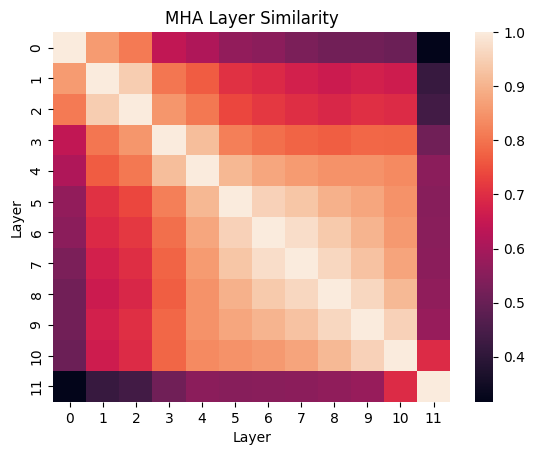

In [80]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = val_mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [81]:
_,_ = adjacent_similarity_stats(val_mha_similarity)

Similarity Scores: [0.8589986, 0.9452298, 0.8520692, 0.91961163, 0.9087894, 0.95231014, 0.97524804, 0.96465194, 0.96527267, 0.9521457, 0.6946553]
Number of High Similar Pairs: 10


In [82]:
_,_ = adjacent_similarity_stats(val_mha_similarity, thresold=0.85)

Similarity Scores: [0.8589986, 0.9452298, 0.8520692, 0.91961163, 0.9087894, 0.95231014, 0.97524804, 0.96465194, 0.96527267, 0.9521457, 0.6946553]
Number of High Similar Pairs: 10


In [83]:
_,_ = adjacent_similarity_stats(val_mha_similarity, thresold=0.9)

Similarity Scores: [0.8589986, 0.9452298, 0.8520692, 0.91961163, 0.9087894, 0.95231014, 0.97524804, 0.96465194, 0.96527267, 0.9521457, 0.6946553]
Number of High Similar Pairs: 8


Text(50.722222222222214, 0.5, 'Layer')

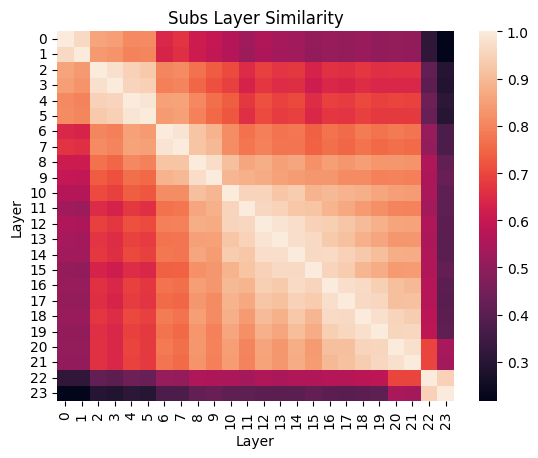

In [84]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [85]:
_,_ = adjacent_similarity_stats(val_sub_similarity)

Similarity Scores: [0.9627165, 0.83582604, 0.9769802, 0.9538829, 0.9870434, 0.84076464, 0.9841243, 0.92039776, 0.9709904, 0.8916768, 0.95211494, 0.95767784, 0.98178005, 0.9743718, 0.9631078, 0.95254433, 0.97448254, 0.9631499, 0.977339, 0.9546533, 0.9775121, 0.6957397, 0.9472711]
Number of High Similar Pairs: 22


In [86]:
_,_ = adjacent_similarity_stats(val_sub_similarity, thresold=0.85)

Similarity Scores: [0.9627165, 0.83582604, 0.9769802, 0.9538829, 0.9870434, 0.84076464, 0.9841243, 0.92039776, 0.9709904, 0.8916768, 0.95211494, 0.95767784, 0.98178005, 0.9743718, 0.9631078, 0.95254433, 0.97448254, 0.9631499, 0.977339, 0.9546533, 0.9775121, 0.6957397, 0.9472711]
Number of High Similar Pairs: 20


In [87]:
_,_ = adjacent_similarity_stats(val_sub_similarity, thresold=0.9)

Similarity Scores: [0.9627165, 0.83582604, 0.9769802, 0.9538829, 0.9870434, 0.84076464, 0.9841243, 0.92039776, 0.9709904, 0.8916768, 0.95211494, 0.95767784, 0.98178005, 0.9743718, 0.9631078, 0.95254433, 0.97448254, 0.9631499, 0.977339, 0.9546533, 0.9775121, 0.6957397, 0.9472711]
Number of High Similar Pairs: 19


Text(50.722222222222214, 0.5, 'Layer')

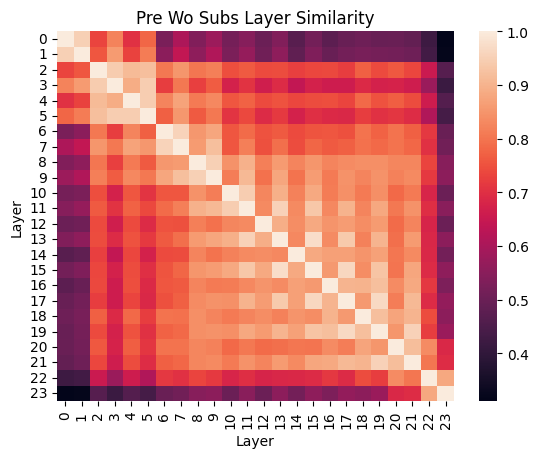

In [88]:
title = "Pre Wo Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_pre_wo_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [89]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity)

Similarity Scores: [0.9501399, 0.7565296, 0.94146854, 0.8877595, 0.94461846, 0.76987696, 0.9557566, 0.8587529, 0.9489784, 0.812094, 0.94396335, 0.83057064, 0.8910577, 0.8300239, 0.88226044, 0.8554571, 0.90266746, 0.8557365, 0.92074656, 0.85112, 0.9185097, 0.8026031, 0.87926865]
Number of High Similar Pairs: 21


In [90]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.9501399, 0.7565296, 0.94146854, 0.8877595, 0.94461846, 0.76987696, 0.9557566, 0.8587529, 0.9489784, 0.812094, 0.94396335, 0.83057064, 0.8910577, 0.8300239, 0.88226044, 0.8554571, 0.90266746, 0.8557365, 0.92074656, 0.85112, 0.9185097, 0.8026031, 0.87926865]
Number of High Similar Pairs: 17


In [91]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.9501399, 0.7565296, 0.94146854, 0.8877595, 0.94461846, 0.76987696, 0.9557566, 0.8587529, 0.9489784, 0.812094, 0.94396335, 0.83057064, 0.8910577, 0.8300239, 0.88226044, 0.8554571, 0.90266746, 0.8557365, 0.92074656, 0.85112, 0.9185097, 0.8026031, 0.87926865]
Number of High Similar Pairs: 9


Text(50.722222222222214, 0.5, 'Layer')

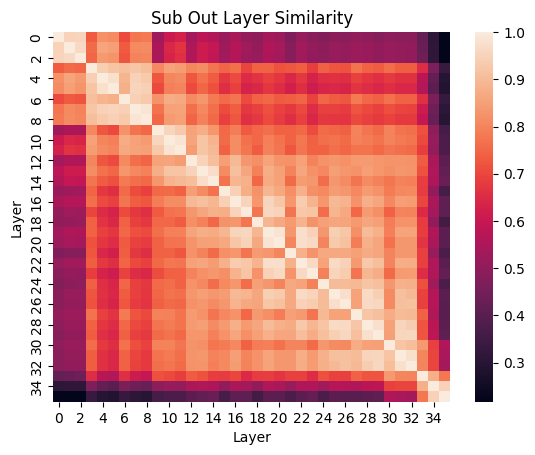

In [92]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [93]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity)

Similarity Scores: [0.9501399, 0.9627165, 0.74623173, 0.94146854, 0.9769802, 0.87962914, 0.94461846, 0.9870434, 0.75091845, 0.9557566, 0.9841243, 0.8438981, 0.9489784, 0.9709904, 0.7691343, 0.94396335, 0.95211494, 0.7744254, 0.8910577, 0.98178005, 0.8015577, 0.88226044, 0.9631078, 0.7951198, 0.90266746, 0.97448254, 0.8511582, 0.92074656, 0.977339, 0.84963965, 0.9185097, 0.9775121, 0.7988061, 0.87926865, 0.9472711]
Number of High Similar Pairs: 29


In [94]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity, thresold=0.85)

Similarity Scores: [0.9501399, 0.9627165, 0.74623173, 0.94146854, 0.9769802, 0.87962914, 0.94461846, 0.9870434, 0.75091845, 0.9557566, 0.9841243, 0.8438981, 0.9489784, 0.9709904, 0.7691343, 0.94396335, 0.95211494, 0.7744254, 0.8910577, 0.98178005, 0.8015577, 0.88226044, 0.9631078, 0.7951198, 0.90266746, 0.97448254, 0.8511582, 0.92074656, 0.977339, 0.84963965, 0.9185097, 0.9775121, 0.7988061, 0.87926865, 0.9472711]
Number of High Similar Pairs: 26


In [95]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity, thresold=0.9)

Similarity Scores: [0.9501399, 0.9627165, 0.74623173, 0.94146854, 0.9769802, 0.87962914, 0.94461846, 0.9870434, 0.75091845, 0.9557566, 0.9841243, 0.8438981, 0.9489784, 0.9709904, 0.7691343, 0.94396335, 0.95211494, 0.7744254, 0.8910577, 0.98178005, 0.8015577, 0.88226044, 0.9631078, 0.7951198, 0.90266746, 0.97448254, 0.8511582, 0.92074656, 0.977339, 0.84963965, 0.9185097, 0.9775121, 0.7988061, 0.87926865, 0.9472711]
Number of High Similar Pairs: 21


### Using Training Data using Whole Sequence

In [44]:
reps_similarity, atts_similarity, mha_similarity, sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:41<00:00,  2.80it/s]

  Reps Similarity Stats:
    Average: 0.989591
    Highest: 0.999240
    Lowest:  0.967765

  Atts Similarity Stats:
    Average: 0.944147
    Highest: 0.991294
    Lowest:  0.762895
  MHA Similarity Stats:
    Average: 0.983106
    Highest: 0.998300
    Lowest:  0.953689
  Sublayer Similarity Stats:
    Average: 0.970021
    Highest: 0.987302
    Lowest:  0.958911


In [41]:
reps_similarity, atts_similarity, sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:36<00:00,  3.15it/s]

  Reps Similarity Stats:
    Average: 0.989591
    Highest: 0.999240
    Lowest:  0.967765

  Atts Similarity Stats:
    Average: 0.944147
    Highest: 0.991294
    Lowest:  0.762895
  Sublayer Similarity Stats:
    Average: 0.810862
    Highest: 0.962792
    Lowest:  0.402067


Text(50.722222222222214, 0.5, 'Layer')

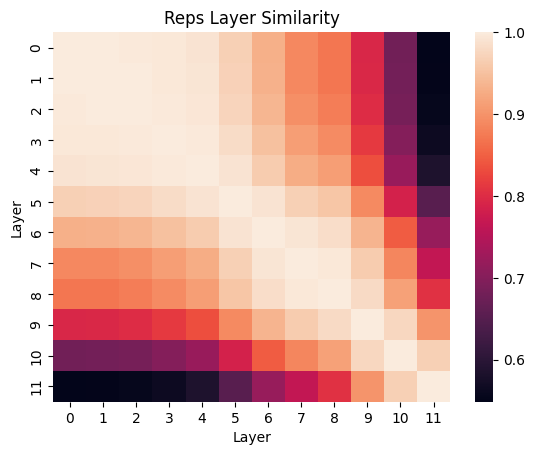

In [45]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

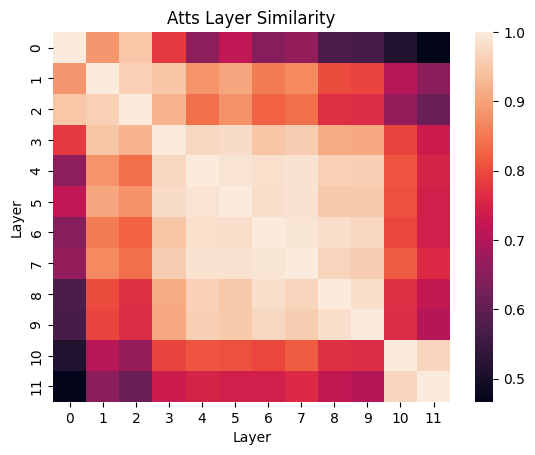

In [46]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

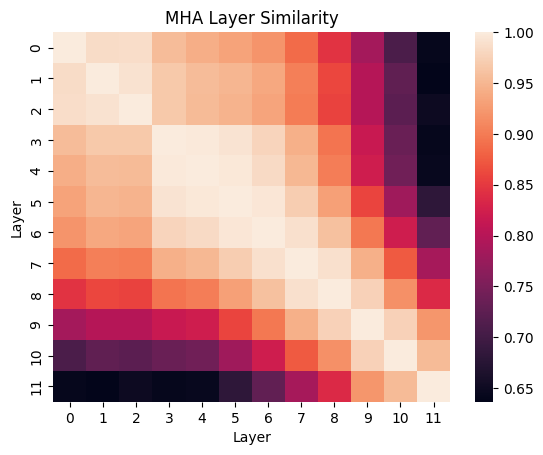

In [47]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

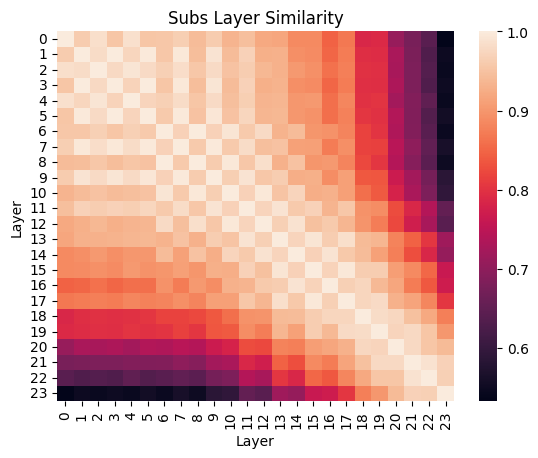

In [48]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

### Using Val Data using Whole Sequence

In [49]:
val_reps_similarity, val_atts_similarity, val_mha_similarity, val_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
val_reps_stats = cka_eval.similarity_stats(val_reps_similarity)
val_atts_stats = cka_eval.similarity_stats(val_atts_similarity)
val_mha_stats  = cka_eval.similarity_stats(val_mha_similarity)
val_subs_stats = cka_eval.similarity_stats(val_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {val_reps_stats['average']:.6f}")
print(f"    Highest: {val_reps_stats['max']:.6f}")
print(f"    Lowest:  {val_reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {val_atts_stats['average']:.6f}")
print(f"    Highest: {val_atts_stats['max']:.6f}")
print(f"    Lowest:  {val_atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {val_mha_stats['average']:.6f}")
print(f"    Highest: {val_mha_stats['max']:.6f}")
print(f"    Lowest:  {val_mha_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {val_subs_stats['average']:.6f}")
print(f"    Highest: {val_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 13/13 [00:04<00:00,  2.83it/s]

  Reps Similarity Stats:
    Average: 0.991503
    Highest: 0.999282
    Lowest:  0.970845

  Atts Similarity Stats:
    Average: 0.946210
    Highest: 0.991978
    Lowest:  0.770506
  MHA Similarity Stats:
    Average: 0.983591
    Highest: 0.998318
    Lowest:  0.944361
  Sublayer Similarity Stats:
    Average: 0.968635
    Highest: 0.984541
    Lowest:  0.956600


Text(50.722222222222214, 0.5, 'Layer')

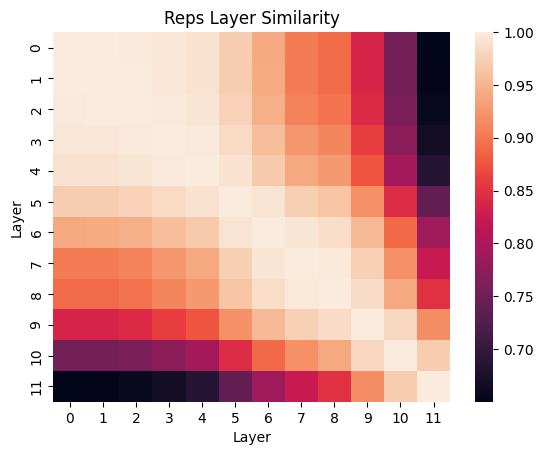

In [50]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = val_reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

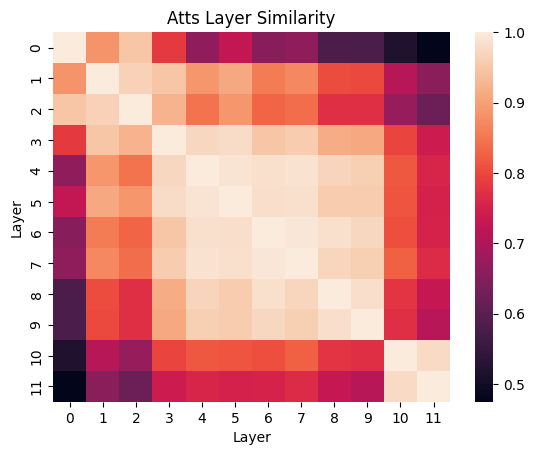

In [51]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = val_atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

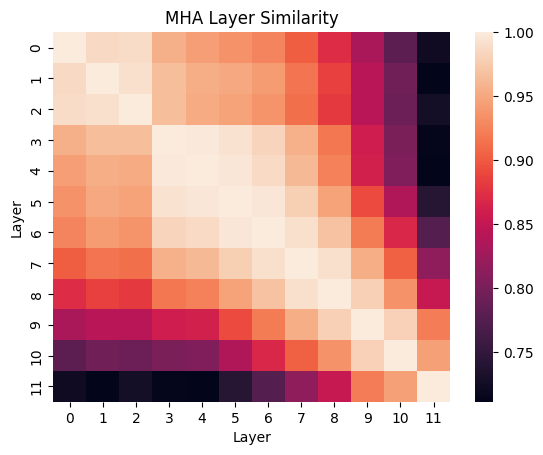

In [52]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = val_mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

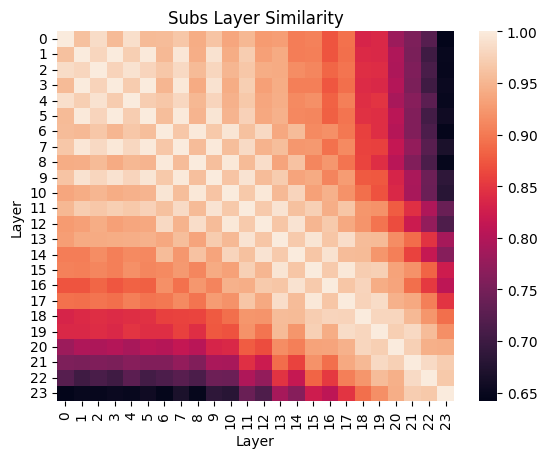

In [53]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

### Using Training Data for Heads Redundancy

In [96]:
headsCka_eval

In [97]:
outputs.attentions['attention_head'][0].shape

torch.Size([32, 12, 167, 167])

In [98]:
outputs.attentions['attention_head'][11].shape

torch.Size([32, 12, 167, 167])

In [99]:
from CKA import CudaCKA

In [100]:
from tqdm import tqdm

In [101]:
class TestHeadRedundancyEval:
    def __init__(self, device):
        self.cuda_cka = CudaCKA(device)
 
    def collect_selected_layer_head_matrices(self, atts, layer_indices):
        """
        atts: list of length L, each (batch, heads, seq_q, seq_k)
        layer_indices: which layers to include (e.g. [3], [0,1,2], or
                       None for all layers)
 
        Returns:
            matrices: list of (batch, seq_q, seq_k) tensors, UNFLATTENED.
                      Sentence-level CKA needs the (n, n) shape intact --
                      do not flatten these.
            labels: list of (layer_idx, head_idx) tuples, same order/length
                    as matrices. Required to interpret rows/cols of the
                    returned similarity matrix once more than one layer
                    is involved.
        """
        if layer_indices is None:
            layer_indices = [i for i in range(len(atts))]  # fixed: missing ')'
 
        matrices = []
        labels = []
        for layer_idx in layer_indices:
            layer_att = atts[layer_idx]  # (batch, heads, seq_q, seq_k)
            heads = layer_att.shape[1]
            for h in range(heads):
                matrices.append(layer_att[:, h, :, :])
                labels.append((layer_idx, h))
        return matrices, labels
 
    def _accumulate_batch(self, matrices, attention_mask, scores_accum):
        """
        Adds this batch's per-sentence CKA sums into scores_accum (in place)
        and returns how many valid sentences (n_valid >= 2) contributed.
 
        Diagonal entries are CKA(head_i, head_i) for each sentence, which
        is always exactly 1.0 -- so after normalizing by n_valid_sentences
        the diagonal stays exactly 1.0, guaranteed to be the max of every
        row/column. No special-casing needed for "same head = highest
        similarity"; it falls out of CKA's own definition as long as every
        (i, i) pair is computed the same way as every (i, j) pair below.
        """
        M = len(matrices)
        batch = matrices[0].shape[0]
        n_valid_sentences = 0
 
        with torch.no_grad():
            for b in range(batch):
                # Padding-side agnostic: works regardless of left/right padding.
                valid_idx = attention_mask[b].bool()
                n_valid = int(valid_idx.sum().item())
 
                # Guard against degenerate very-short sentences where
                # linear_CKA's variance terms can be ~0 -> NaN.
                if n_valid < 2:
                    continue
                n_valid_sentences += 1
 
                for i in range(M):
                    Ai = matrices[i][b][valid_idx][:, valid_idx]  # (n_valid, n_valid)
                    for j in range(i, M):
                        Bj = matrices[j][b][valid_idx][:, valid_idx]
                        val = self.cuda_cka.linear_CKA(Ai, Bj).detach()
                        scores_accum[i, j] += val
                        if i != j:
                            scores_accum[j, i] += val
                        # i == j case (diagonal): added once, correctly,
                        # via the scores_accum[i, j] += val line above.
 
        return n_valid_sentences
 
    def att_head_redundancy_estimate(self, model, dataloader, device,
                                      max_iter=float("Inf"), layer_indices=None,
                                      attention_mask_key="attention_mask"):
        """
        Runs sentence-level CKA head-redundancy estimation over an entire
        dataloader. Diagonal of the returned matrix is guaranteed to be
        1.0 (a head is always maximally similar to itself), so every
        row/column's max similarity is its own diagonal entry.
 
        Returns:
            scores: (M, M) numpy array, M = len(layer_indices or all)*heads
            labels: list of (layer_idx, head_idx), same order as rows/cols
        """
        model.set_use_module_grafting(False)
        model.set_use_scc_status(False)
 
        n_batch = len(dataloader)
        n_steps = min(n_batch, max_iter) if max_iter != float("Inf") else n_batch
        progress_bar = tqdm(range(n_steps), desc="CKA Sublayer Evaluation")
 
        model.eval()
 
        scores = None
        labels = None
        total_valid_sentences = 0
 
        for step, batch in enumerate(dataloader):
            if step == max_iter:
                break
 
            batch = {k: v.to(device) for k, v in batch.items()}
            attention_mask = batch[attention_mask_key]
 
            with torch.no_grad():
                output = model(**batch)
 
            atts = output.attentions["attention_head"]  # list of (batch, heads, seq_q, seq_k)
 
            matrices, labels = self.collect_selected_layer_head_matrices(atts, layer_indices)
 
            if scores is None:
                M = len(matrices)
                scores = torch.zeros(M, M, device=matrices[0].device)
 
            n_valid = self._accumulate_batch(matrices, attention_mask, scores)
            total_valid_sentences += n_valid
 
            progress_bar.update(1)
 
        if total_valid_sentences == 0:
            scores.fill_(float("nan"))
        else:
            scores = scores / total_valid_sentences
 
        # Sanity: diagonal should be (numerically) 1.0 -- confirms the
        # "same head = highest similarity" property holds by construction.
        return scores.cpu().numpy(), labels

In [102]:
test = TestHeadRedundancyEval(device)

In [103]:
scores, labels = test.att_head_redundancy_estimate(model, train_dataloader, device, layer_indices=[10, 11], max_iter=5)

CKA Sublayer Evaluation: 100%|██████████| 5/5 [00:14<00:00,  2.80s/it]


In [104]:
for batch in train_dataloader:
    batch = {k: v.to(device) for k, v in batch.items()}
    attention_mask = batch['attention_mask']
    with torch.no_grad():
        output = model(**batch)
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 180]),
 'token_type_ids': torch.Size([32, 180]),
 'attention_mask': torch.Size([32, 180])}

In [105]:
len(outputs.attentions['attention_head'])

12

In [106]:
outputs.attentions['attention_head'][0].shape

torch.Size([32, 12, 167, 167])

In [107]:
matrices, labels = test.collect_selected_layer_head_matrices(outputs.attentions['attention_head'], [0, 1])

In [108]:
labels

[(0, 0),
 (0, 1),
 (0, 2),
 (0, 3),
 (0, 4),
 (0, 5),
 (0, 6),
 (0, 7),
 (0, 8),
 (0, 9),
 (0, 10),
 (0, 11),
 (1, 0),
 (1, 1),
 (1, 2),
 (1, 3),
 (1, 4),
 (1, 5),
 (1, 6),
 (1, 7),
 (1, 8),
 (1, 9),
 (1, 10),
 (1, 11)]

In [109]:
len(matrices)

24

In [110]:
matrices[0].shape

torch.Size([32, 167, 167])

In [111]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Heads')

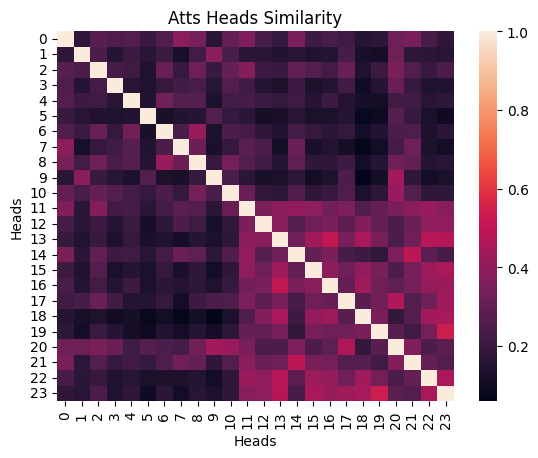

In [112]:
title = "Atts Heads Similarity"
plt.title(title)
sn.heatmap(data = scores)
plt.xlabel("Heads")
plt.ylabel("Heads")

# 6. Sensitivity Score Analysis

In [113]:
from structure_prune_helper import register_importance_masks

In [114]:
register_importance_masks(
    model, device, register_pre_wo_layer=True, register_mha=True, register_mlp=True, register_mha_layer=True, register_mlp_layer=True
)

  Layer 0: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 1: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 2: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 3: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 4: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 5: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 6: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 7: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 8: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 9: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 10: Register

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [115]:
from structure_prune_helper import compute_layer_importance_scores

In [116]:
pre_wo_importance, mha_importance, ffn_importance, head_importance, neuron_importance, sublayer_importance =compute_layer_importance_scores(
    model, train_dataloader, device, max_batches=115,
    compute_mha=True, compute_ffn=True, compute_heads=True,
    compute_neurons=True, compute_pre_wo=True,
    display_separate=True, display_combined=True, display_pruning_order=True,
)

Computing importance (pre-WO layer, MHA layer, FFN layer, heads, neurons): 100%|██████████| 78/78 [00:18<00:00,  4.19it/s]


Layer Importance Summary (separate):
          Layer  Pre-WO(layer)     MHA(layer)     FFN(layer)    Heads(mean)  Neurons(mean)
  ------------------------------------------------------------------------------------------
  0                     0.4489         0.4749         0.4842         0.0000         0.0000
  1                     0.4118         0.4391         0.4328         0.0000         0.0000
  2                     0.3678         0.4109         0.4950         0.0000         0.0000
  3                     0.4206         0.4292         0.5197         0.0000         0.0000
  4                     0.3783         0.4009         0.5583         0.0000         0.0000
  5                     0.3888         0.4363         0.7575         0.0000         0.0000
  6                     0.3881         0.4668         0.6426         0.0000         0.0000
  7                     0.5253         0.6258         0.8021         0.0000         0.0000
  8                     0.9426         0.8671     

In [117]:
pre_wo_importance

array([0.4488533 , 0.41184947, 0.36779305, 0.42060483, 0.37832567,
       0.38879016, 0.38811833, 0.5252586 , 0.9425836 , 0.6076852 ,
       1.        , 0.34352887], dtype=float32)

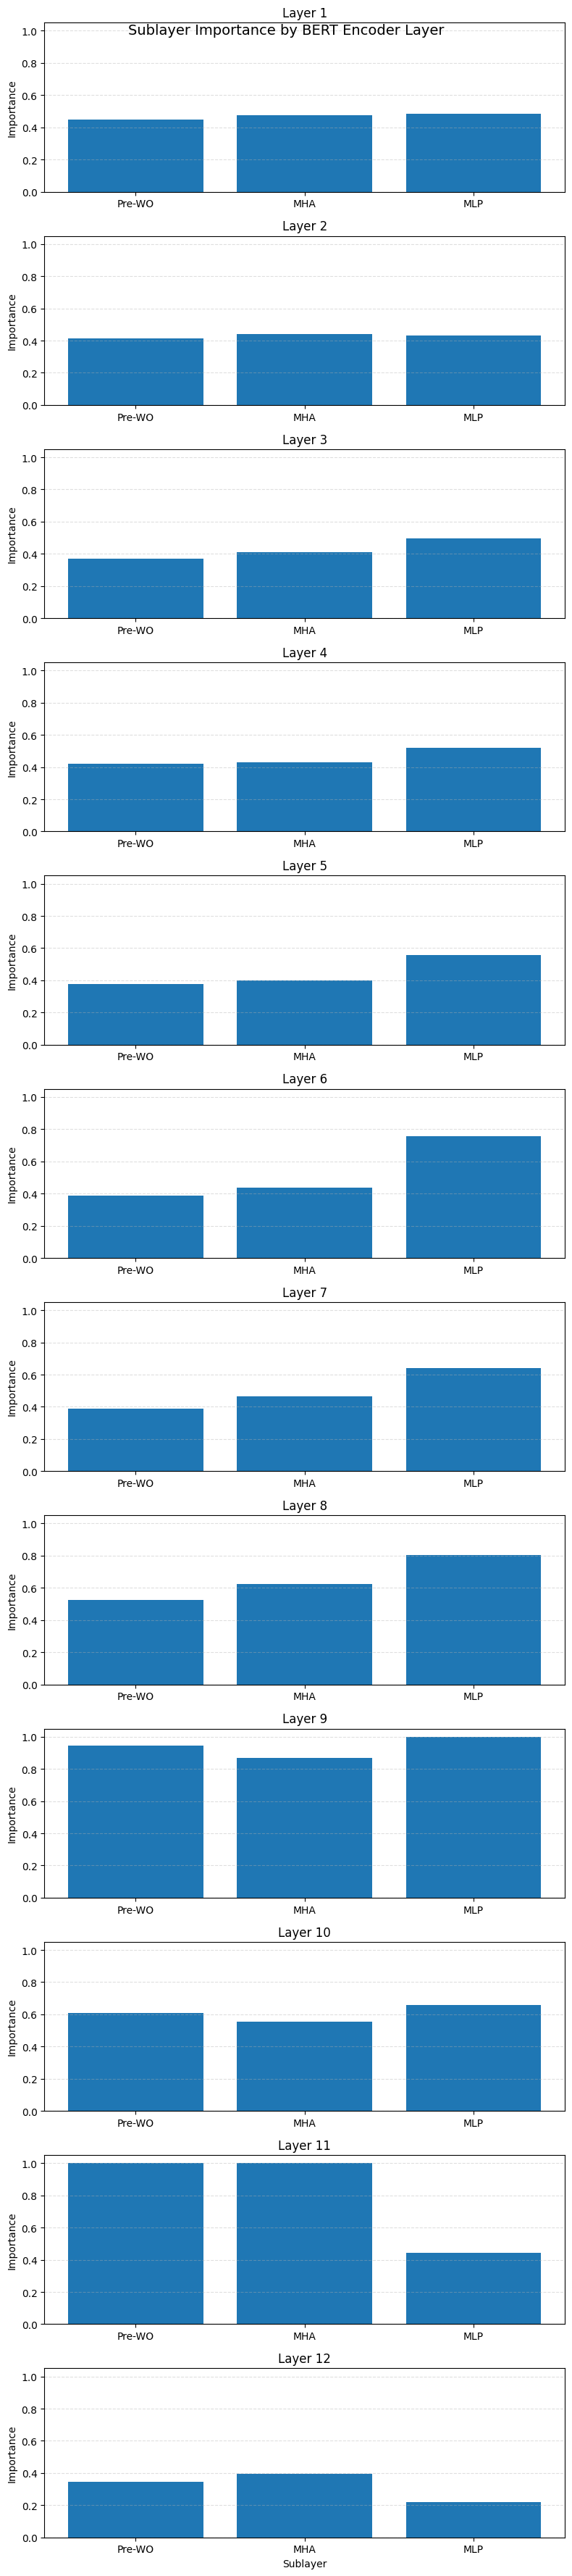

In [118]:
import matplotlib.pyplot as plt
import numpy as np

# Importance scores returned by compute_layer_importance_scores()
# pre_wo_importance, mha_importance, ffn_importance

n_layers = len(pre_wo_importance)

fig, axes = plt.subplots(
    n_layers, 1,
    figsize=(8, 3 * n_layers),
    sharey=True
)

# Handle the case of a model with only one layer
if n_layers == 1:
    axes = [axes]

labels = ["Pre-WO", "MHA", "MLP"]

for layer_idx, ax in enumerate(axes):
    scores = [
        pre_wo_importance[layer_idx],
        mha_importance[layer_idx],
        ffn_importance[layer_idx],
    ]

    ax.bar(labels, scores)
    ax.set_title(f"Layer {layer_idx + 1}")
    ax.set_ylabel("Importance")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[-1].set_xlabel("Sublayer")
fig.suptitle("Sublayer Importance by BERT Encoder Layer", fontsize=14)
plt.tight_layout()
plt.show()

### Using Training Data on CLS Token only

In [119]:
reps_similarity, atts_similarity, mha_similarity, pre_wo_similarity, sub_similarity, pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
pre_wo_stats = cka_eval.similarity_stats(pre_wo_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)
pre_wo_subs_stats = cka_eval.similarity_stats(pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {pre_wo_stats['average']:.6f}")
print(f"    Highest: {pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 78/78 [00:43<00:00,  1.78it/s]

  Reps Similarity Stats:
    Average: 0.878069
    Highest: 0.961004
    Lowest:  0.569818

  Atts Similarity Stats:
    Average: 0.969374
    Highest: 0.996457
    Lowest:  0.916857
  MHA Similarity Stats:
    Average: 0.899813
    Highest: 0.974735
    Lowest:  0.682067
  Pre Wo Similarity Stats:
    Average: 0.833225
    Highest: 0.907538
    Lowest:  0.729170
  Sublayer Similarity Stats:
    Average: 0.935216
    Highest: 0.985841
    Lowest:  0.673609
  Pre Wo Sublayer Similarity Stats:
    Average: 0.868839
    Highest: 0.953235
    Lowest:  0.756750


In [120]:
sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

sub_out_stats = cka_eval.similarity_stats(sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {sub_out_stats['average']:.6f}")
print(f"    Highest: {sub_out_stats['max']:.6f}")
print(f"    Lowest:  {sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 78/78 [00:29<00:00,  2.61it/s]

  Sub Out Similarity Stats:
    Average: 0.896009
    Highest: 0.985967
    Lowest:  0.745380


In [121]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Layer')

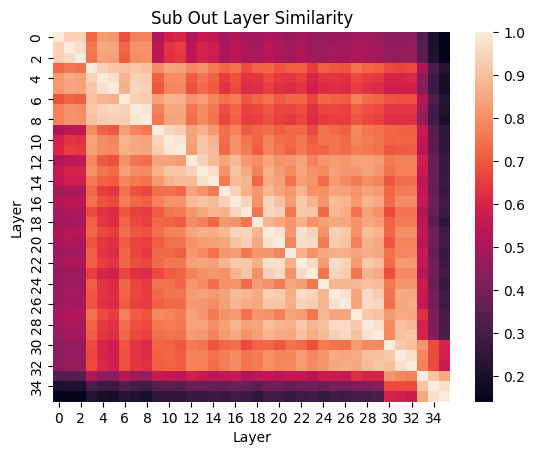

In [122]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [123]:
sub_out_similarity.shape 

(36, 36)

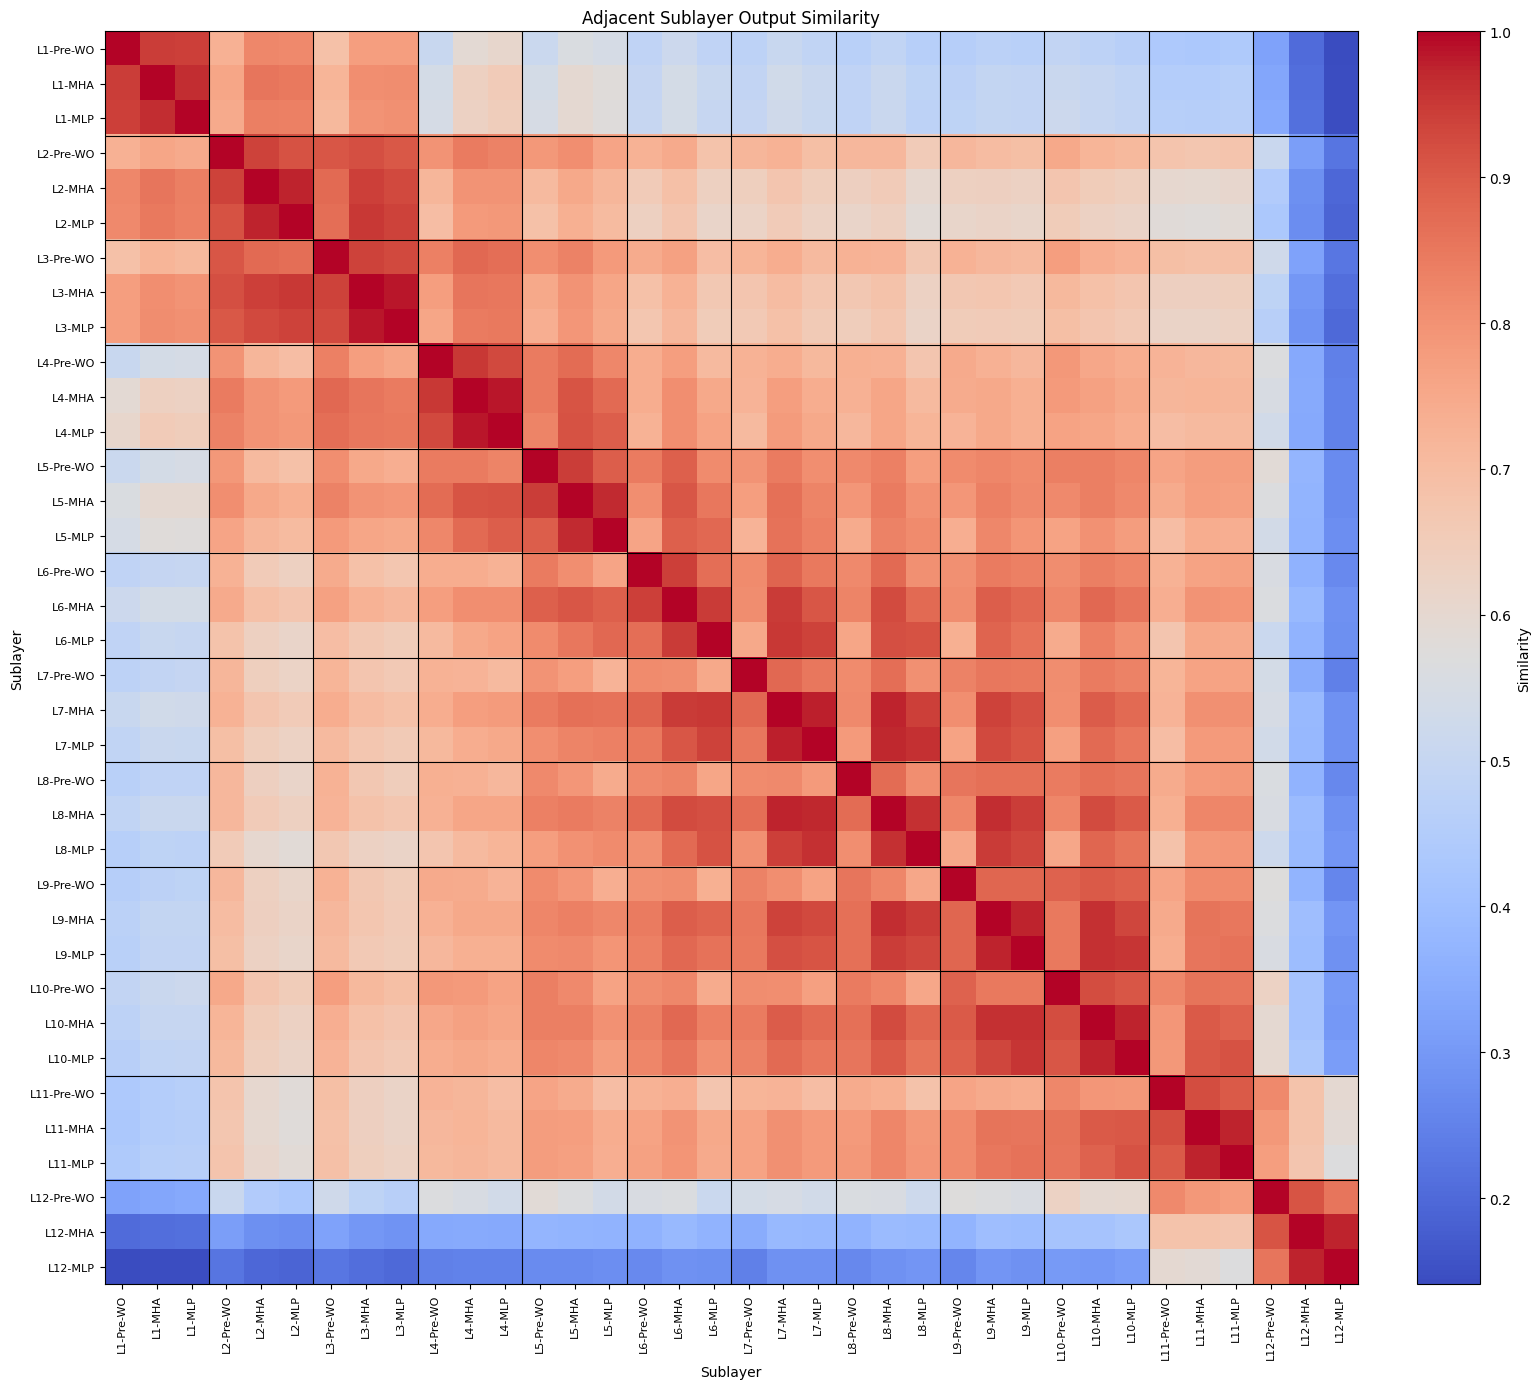

In [124]:
import matplotlib.pyplot as plt
import numpy as np

# sub_out_similarity: (36, 36)
n_layers = 12
sublayers = ["Pre-WO", "MHA", "MLP"]

labels = [
    f"L{layer + 1}-{sub}"
    for layer in range(n_layers)
    for sub in sublayers
]

fig, ax = plt.subplots(figsize=(16, 14))

im = ax.imshow(
    sub_out_similarity,
    cmap="coolwarm",
    interpolation="nearest",
    aspect="equal"
)

# Label every sublayer
ax.set_xticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_yticks(np.arange(len(labels)))
ax.set_yticklabels(labels, fontsize=8)

# Add boundaries between encoder layers
for boundary in range(3, n_layers * 3, 3):
    ax.axhline(boundary - 0.5, color="black", linewidth=0.8)
    ax.axvline(boundary - 0.5, color="black", linewidth=0.8)

# Color scale
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Similarity")

ax.set_title("Adjacent Sublayer Output Similarity")
ax.set_xlabel("Sublayer")
ax.set_ylabel("Sublayer")

plt.tight_layout()
plt.show()